# Lab 07 – Q1: Image Transformations

**What this notebook does (in simple words):**
An image is just a grid of pixels. A *transformation* is a rule that tells every pixel
"move to a new position". Depending on the rule, the picture can slide, spin, grow, lean over,
or even look like it was photographed from a different angle.

| Part | Topic | One-line idea |
|---|---|---|
| (a) | 2D transformations | translate, rotate, scale, shear an image |
| (b) | 3D transformation | rotate / move a 3D shape along x, y, z |
| (c) | Homogeneous coordinates | add a "1" to every point so that *all* moves become matrix multiplications |
| (d) | Affine transformation | lines stay straight **and parallel lines stay parallel** |
| (e) | Projective transformation (homography) | straighten a slanted book so that it looks flat |

Everything runs top to bottom. If the sample photo is not on your computer, the next cell downloads it
automatically (and falls back to a generated picture if you are offline).

## 0. Setup and input image
We need three libraries:
* **OpenCV (`cv2`)** – does the actual image warping,
* **NumPy** – matrices and maths,
* **Matplotlib** – shows the pictures.

The input is a photo of a castle (Sceaux Castle, a public dataset image). Any other photo works too –
just change `IMAGE_PATH`.

Image size used: width = 480  height = 361


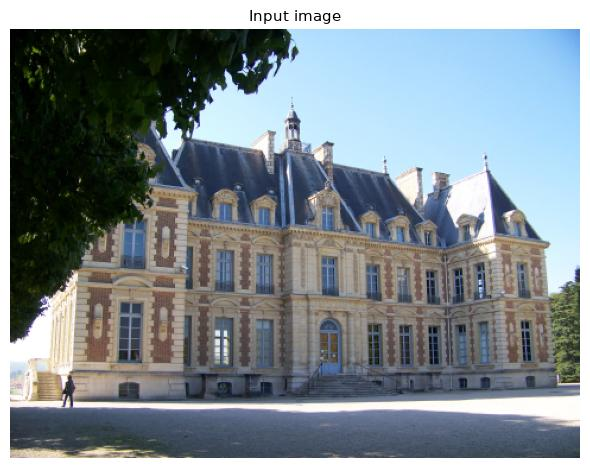

In [1]:
import os, urllib.request
import numpy as np
import cv2
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
try:   # smaller notebook file: store the inline plots as JPEG instead of PNG
    get_ipython().run_line_magic("config", "InlineBackend.figure_formats = ['jpeg']")
except Exception:
    pass
os.makedirs("data", exist_ok=True)
os.makedirs("outputs_q1", exist_ok=True)

IMAGE_PATH = "data/sample_photo.jpg"
IMAGE_URL = "https://raw.githubusercontent.com/openMVG/ImageDataset_SceauxCastle/master/images/100_7100.JPG"

def get_sample_image():
    # 1) use local file, 2) else download it, 3) else make a synthetic picture
    if not os.path.exists(IMAGE_PATH):
        try:
            urllib.request.urlretrieve(IMAGE_URL, IMAGE_PATH)
        except Exception as e:
            print("Download failed (", e, ") -> using a generated picture instead")
    img = cv2.imread(IMAGE_PATH)
    if img is None:
        img = np.full((400, 600, 3), 235, np.uint8)
        for i in range(0, 600, 40):
            cv2.line(img, (i, 0), (i, 399), (200, 120, 60), 2)
        for j in range(0, 400, 40):
            cv2.line(img, (0, j), (599, j), (60, 120, 200), 2)
        cv2.putText(img, "SAMPLE", (170, 220), cv2.FONT_HERSHEY_SIMPLEX, 2.5, (0, 0, 0), 6)
    return img

def show(images, titles, cols=None, figsize=None, suptitle=None):
    # helper: show a list of BGR images in a row/grid
    n = len(images)
    cols = cols or n
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize or (5 * cols, 4 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(t, fontsize=11)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=14)
    plt.tight_layout()
    plt.show()

orig = get_sample_image()
# make it smaller so everything is quick and fits the screen
scale = 480 / orig.shape[1]
img = cv2.resize(orig, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
h, w = img.shape[:2]
print("Image size used: width =", w, " height =", h)
show([img], ["Input image"], figsize=(6, 5))

---
# (a) 2D transformations: translation, rotation, scaling, shearing

### The idea
Every pixel has a position $(x, y)$. A 2D transformation moves it to a new position $(x', y')$.
Using a **3×3 matrix** $M$ (explained properly in part (c)) we can write all of them in the same way:

$$
\begin{bmatrix} x' \\ y' \\ 1 \end{bmatrix} = M \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}
$$

| Transformation | What happens | Matrix $M$ |
|---|---|---|
| **Translation** | slide the picture by $t_x, t_y$ | $\begin{bmatrix}1&0&t_x\\0&1&t_y\\0&0&1\end{bmatrix}$ |
| **Rotation** | spin by angle $\theta$ | $\begin{bmatrix}\cos\theta&-\sin\theta&0\\ \sin\theta&\cos\theta&0\\0&0&1\end{bmatrix}$ |
| **Scaling** | grow / shrink by $s_x, s_y$ | $\begin{bmatrix}s_x&0&0\\0&s_y&0\\0&0&1\end{bmatrix}$ |
| **Shearing** | lean the picture sideways ($sh_x$) or up/down ($sh_y$) | $\begin{bmatrix}1&sh_x&0\\sh_y&1&0\\0&0&1\end{bmatrix}$ |

OpenCV only needs the **top two rows** (a 2×3 matrix) and the function `cv2.warpAffine` does the rest.

To see how the *shape* changes clearly, I put the picture on a bigger grey canvas and draw a red frame around it.
Rotation, scaling and shearing are done **about the centre** of the image (otherwise they would swing around the top-left corner).

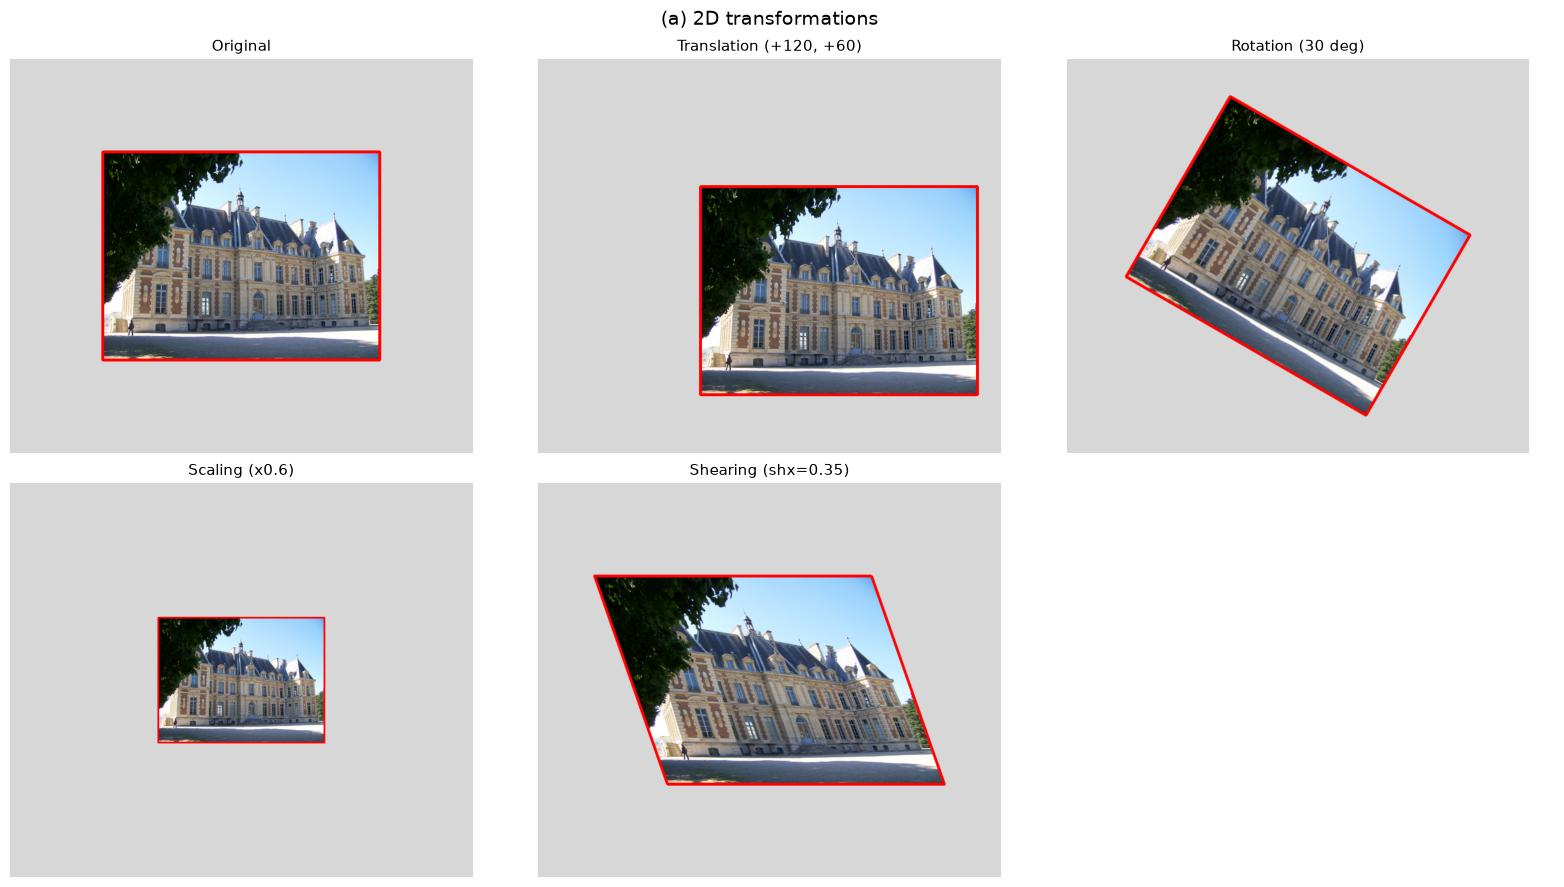

In [2]:
# ---- put the image on a bigger canvas so that moved / rotated pictures stay visible ----
PAD = 160
canvas = np.full((h + 2 * PAD, w + 2 * PAD, 3), 215, np.uint8)
canvas[PAD:PAD + h, PAD:PAD + w] = img
cv2.rectangle(canvas, (PAD, PAD), (PAD + w - 1, PAD + h - 1), (0, 0, 255), 3)   # red frame
H_c, W_c = canvas.shape[:2]
center = (W_c / 2, H_c / 2)

def T(tx, ty):
    return np.array([[1, 0, tx], [0, 1, ty], [0, 0, 1]], float)

def R(deg):
    a = np.deg2rad(deg)
    return np.array([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0], [0, 0, 1]], float)

def S(sx, sy):
    return np.array([[sx, 0, 0], [0, sy, 0], [0, 0, 1]], float)

def SH(shx, shy):
    return np.array([[1, shx, 0], [shy, 1, 0], [0, 0, 1]], float)

def about_center(M):
    # move centre to origin -> apply M -> move back
    return T(*center) @ M @ T(-center[0], -center[1])

def warp(M3):
    return cv2.warpAffine(canvas, M3[:2], (W_c, H_c), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=(215, 215, 215))

M_translate = T(120, 60)
M_rotate    = about_center(R(30))
M_scale     = about_center(S(0.6, 0.6))
M_shear     = about_center(SH(0.35, 0.0))

results = {
    "Translation (+120, +60)": warp(M_translate),
    "Rotation (30 deg)":       warp(M_rotate),
    "Scaling (x0.6)":          warp(M_scale),
    "Shearing (shx=0.35)":     warp(M_shear),
}
show([canvas] + list(results.values()), ["Original"] + list(results.keys()), cols=3,
     figsize=(16, 9), suptitle="(a) 2D transformations")

for name, im in results.items():
    cv2.imwrite("outputs_q1/a_" + name.split()[0].lower() + ".png", im)

### Check it with numbers: where do the 4 image corners go?
We multiply each corner of the (red-framed) image by each matrix. This is exactly what the warp does to every pixel.

In [3]:
corners = np.array([[PAD, PAD], [PAD + w, PAD], [PAD + w, PAD + h], [PAD, PAD + h]], float)
corners_h = np.hstack([corners, np.ones((4, 1))]).T        # 3x4  (homogeneous)

for name, M in [("Translation", M_translate), ("Rotation", M_rotate), ("Scaling", M_scale), ("Shearing", M_shear)]:
    new = (M @ corners_h)[:2].T
    print(f"{name}\n  matrix:\n{M}\n  corners before -> after")
    for b, a in zip(corners, new):
        print(f"    ({b[0]:6.1f},{b[1]:6.1f})  ->  ({a[0]:6.1f},{a[1]:6.1f})")
    print()

Translation
  matrix:
[[  1.   0. 120.]
 [  0.   1.  60.]
 [  0.   0.   1.]]
  corners before -> after
    ( 160.0, 160.0)  ->  ( 280.0, 220.0)
    ( 640.0, 160.0)  ->  ( 760.0, 220.0)
    ( 640.0, 521.0)  ->  ( 760.0, 581.0)
    ( 160.0, 521.0)  ->  ( 280.0, 581.0)

Rotation
  matrix:
[[   0.866   -0.5    223.84 ]
 [   0.5      0.866 -154.382]
 [   0.       0.       1.   ]]
  corners before -> after
    ( 160.0, 160.0)  ->  ( 282.4,  64.2)
    ( 640.0, 160.0)  ->  ( 698.1, 304.2)
    ( 640.0, 521.0)  ->  ( 517.6, 616.8)
    ( 160.0, 521.0)  ->  ( 101.9, 376.8)

Scaling
  matrix:
[[  0.6   0.  160. ]
 [  0.    0.6 136.2]
 [  0.    0.    1. ]]
  corners before -> after
    ( 160.0, 160.0)  ->  ( 256.0, 232.2)
    ( 640.0, 160.0)  ->  ( 544.0, 232.2)
    ( 640.0, 521.0)  ->  ( 544.0, 448.8)
    ( 160.0, 521.0)  ->  ( 256.0, 448.8)

Shearing
  matrix:
[[   1.       0.35  -119.175]
 [   0.       1.       0.   ]
 [   0.       0.       1.   ]]
  corners before -> after
    ( 160.0, 160.0)  -

### What we observe
* **Translation** – position changes, shape and size stay exactly the same.
* **Rotation** – position of the corners changes, but side lengths and right angles stay the same (the rectangle is only turned).
* **Scaling** – the rectangle gets smaller (or bigger) but it is still a rectangle with the same angles.
* **Shearing** – the shape itself changes: the rectangle becomes a **parallelogram** (angles are no longer 90°), though opposite sides remain parallel.

---
# (b) 3D transformation: rotate and move along x, y and z

### The idea
A 3D point is $(x, y, z)$. In 3D we rotate around one of the three axes:

$$R_x(\alpha)=\begin{bmatrix}1&0&0\\0&\cos\alpha&-\sin\alpha\\0&\sin\alpha&\cos\alpha\end{bmatrix},\quad
R_y(\beta)=\begin{bmatrix}\cos\beta&0&\sin\beta\\0&1&0\\-\sin\beta&0&\cos\beta\end{bmatrix},\quad
R_z(\gamma)=\begin{bmatrix}\cos\gamma&-\sin\gamma&0\\ \sin\gamma&\cos\gamma&0\\0&0&1\end{bmatrix}$$

and we move (translate) by adding $(t_x, t_y, t_z)$. As in 2D, we put everything into one **4×4 matrix** so rotation and movement can be done with a single multiplication.

As the 3D object I use a small **house** (a box with a roof) because it is not symmetric – so you can *see* every rotation.

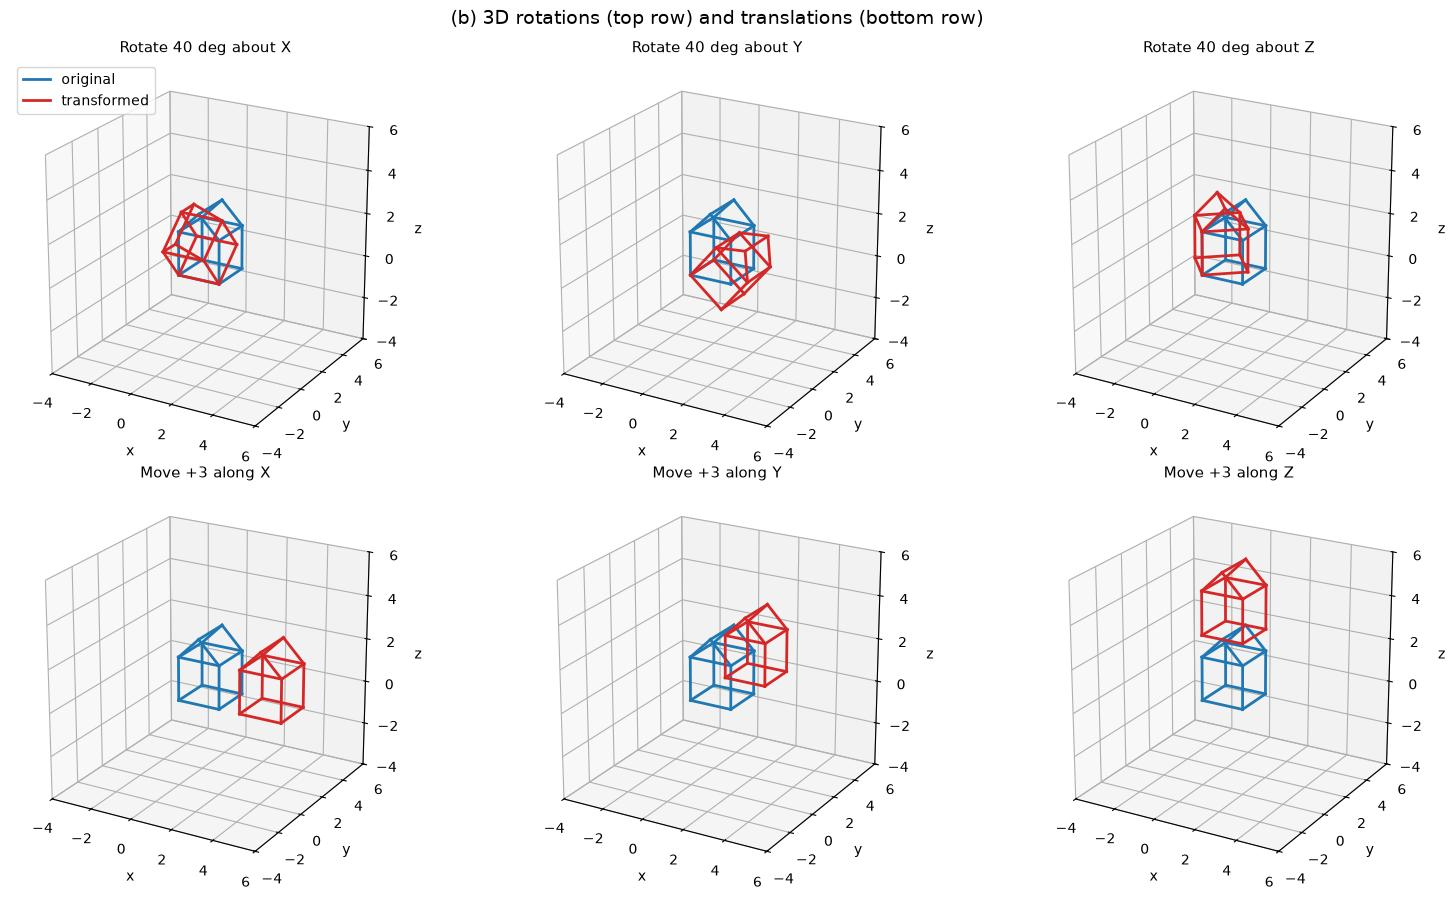

In [4]:
from mpl_toolkits.mplot3d import Axes3D  # noqa

# ---- the object: a house (8 box corners + 2 roof-ridge points) ----
V = np.array([
    [0,0,0],[2,0,0],[2,2,0],[0,2,0],      # 0-3 floor
    [0,0,2],[2,0,2],[2,2,2],[0,2,2],      # 4-7 top of the walls
    [1,0,3],[1,2,3],                      # 8-9 roof ridge
], float)
E = [(0,1),(1,2),(2,3),(3,0), (4,5),(5,6),(6,7),(7,4), (0,4),(1,5),(2,6),(3,7),
     (4,8),(5,8),(6,9),(7,9),(8,9)]

def Rx(d):
    a = np.deg2rad(d); c, s = np.cos(a), np.sin(a)
    return np.array([[1,0,0,0],[0,c,-s,0],[0,s,c,0],[0,0,0,1]], float)
def Ry(d):
    a = np.deg2rad(d); c, s = np.cos(a), np.sin(a)
    return np.array([[c,0,s,0],[0,1,0,0],[-s,0,c,0],[0,0,0,1]], float)
def Rz(d):
    a = np.deg2rad(d); c, s = np.cos(a), np.sin(a)
    return np.array([[c,-s,0,0],[s,c,0,0],[0,0,1,0],[0,0,0,1]], float)
def T3(tx, ty, tz):
    M = np.eye(4); M[:3, 3] = [tx, ty, tz]; return M

def transform_points(P, M4):
    Ph = np.hstack([P, np.ones((len(P), 1))])      # (N,4) homogeneous
    return (M4 @ Ph.T).T[:, :3]

def draw_house(ax, P, color, label=None, lw=2):
    for k, (i, j) in enumerate(E):
        ax.plot(*zip(P[i], P[j]), color=color, lw=lw, label=label if k == 0 else None)

def setup_axes(ax, title, lim=(-4, 6)):
    ax.set_xlim(*lim); ax.set_ylim(*lim); ax.set_zlim(*lim)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
    ax.set_title(title, fontsize=11)
    ax.view_init(elev=22, azim=-60)
    ax.set_box_aspect((1, 1, 1))

fig = plt.figure(figsize=(16, 9))
tests = [
    ("Rotate 40 deg about X", Rx(40)), ("Rotate 40 deg about Y", Ry(40)), ("Rotate 40 deg about Z", Rz(40)),
    ("Move +3 along X", T3(3, 0, 0)),   ("Move +3 along Y", T3(0, 3, 0)),   ("Move +3 along Z", T3(0, 0, 3)),
]
for k, (title, M) in enumerate(tests, 1):
    ax = fig.add_subplot(2, 3, k, projection="3d")
    draw_house(ax, V, "tab:blue", "original")
    draw_house(ax, transform_points(V, M), "tab:red", "transformed")
    setup_axes(ax, title)
    if k == 1: ax.legend(loc="upper left")
plt.suptitle("(b) 3D rotations (top row) and translations (bottom row)", fontsize=14)
plt.tight_layout()
plt.savefig("outputs_q1/b_3d_single_moves.png", dpi=110)
plt.show()

### Combining several moves into one matrix
Because each move is a 4×4 matrix, a whole *sequence* of moves is just **one multiplied matrix**.
The order matters: the matrix written **right-most is applied first**.

Here: first rotate 30° about X, then 45° about Y, then 20° about Z, then slide by (3, 1, 2):

$$M = T \cdot R_z \cdot R_y \cdot R_x$$

Combined 4x4 matrix:
 [[ 0.664  0.036  0.746  3.   ]
 [ 0.242  0.935 -0.26   1.   ]
 [-0.707  0.354  0.612  2.   ]
 [ 0.     0.     0.     1.   ]]

Point 0 (floor corner) moved from [0. 0. 0.] to [3. 1. 2.]
Point 8 (roof tip)     moved from [1. 0. 3.] to [5.904 0.461 3.13 ]

All edge lengths unchanged (rigid motion)? True


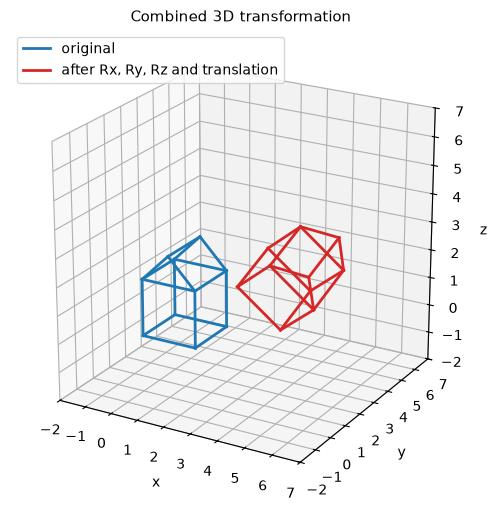

In [5]:
M_total = T3(3, 1, 2) @ Rz(20) @ Ry(45) @ Rx(30)
print("Combined 4x4 matrix:\n", M_total)

V_new = transform_points(V, M_total)
print("\nPoint 0 (floor corner) moved from", V[0], "to", V_new[0])
print("Point 8 (roof tip)     moved from", V[8], "to", V_new[8])

# lengths of the edges must stay the same for a rotation+translation (rigid motion)
len_before = [np.linalg.norm(V[i] - V[j]) for i, j in E]
len_after  = [np.linalg.norm(V_new[i] - V_new[j]) for i, j in E]
print("\nAll edge lengths unchanged (rigid motion)?", np.allclose(len_before, len_after))

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
draw_house(ax, V, "tab:blue", "original")
draw_house(ax, V_new, "tab:red", "after Rx, Ry, Rz and translation")
setup_axes(ax, "Combined 3D transformation", lim=(-2, 7))
ax.legend(loc="upper left")
plt.savefig("outputs_q1/b_3d_combined.png", dpi=110)
plt.show()

### What we observe
* A rotation about an axis keeps the coordinate on **that** axis unchanged and spins the other two.
* A translation just slides the whole house – shape and size are identical.
* The house is never stretched: **edge lengths stay the same** (it is a *rigid* motion), only its position and orientation change.

### Bonus: what a camera "sees" of this 3D object
A camera flattens 3D to 2D by dividing by depth ($x_{img}=f\,x/z$, $y_{img}=f\,y/z$) – this is the link between part (b) and the projective transformation in part (e).

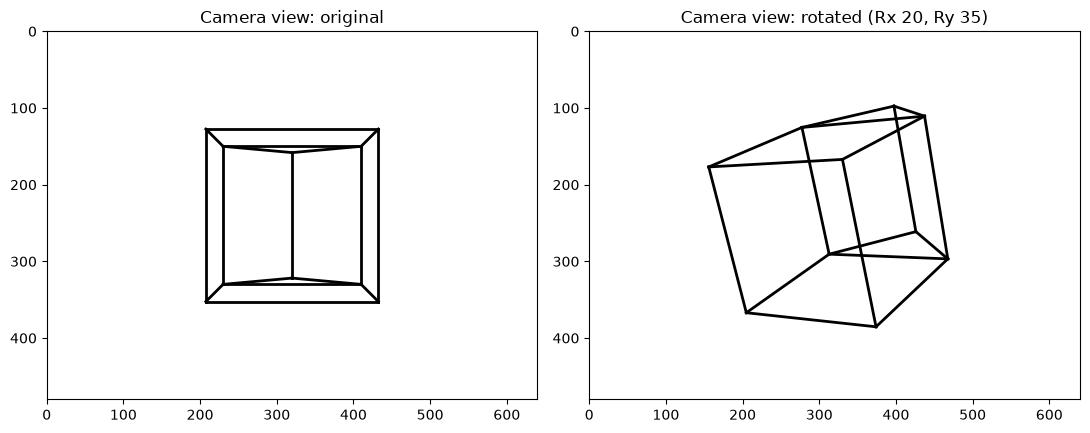

In [6]:
def project(P, f=900, cx=320, cy=240, z_shift=9):
    # simple pinhole camera: push object away from the camera, then divide by depth
    Pc = P.copy(); Pc[:, 2] += z_shift
    return np.stack([f * Pc[:, 0] / Pc[:, 2] + cx, f * Pc[:, 1] / Pc[:, 2] + cy], axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, P, t in zip(axes, [V - [1, 1, 1], transform_points(V - [1, 1, 1], Ry(35) @ Rx(20))],
                    ["Camera view: original", "Camera view: rotated (Rx 20, Ry 35)"]):
    p2 = project(P)
    for i, j in E:
        ax.plot([p2[i, 0], p2[j, 0]], [p2[i, 1], p2[j, 1]], "k-", lw=2)
    ax.set_title(t); ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xlim(0, 640); ax.set_ylim(480, 0)
plt.tight_layout(); plt.show()

---
# (c) Homogeneous coordinates

### What are they?
A normal 2D point is $(x, y)$. Its **homogeneous** form just adds a third number:

$$(x, y) \;\longrightarrow\; \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}$$

To go back we divide by the last number: $\begin{bmatrix}X\\Y\\W\end{bmatrix} \to (X/W,\; Y/W)$.

### Why do we need the extra coordinate in computer vision? (simple explanation)
1. **Translation cannot be written as a 2×2 matrix.** Rotation and scaling can ($p' = A p$), but moving is *adding* something ($p' = A p + t$).
   With the extra "1", adding becomes multiplying, so **translation, rotation, scaling, shear all become one matrix multiplication**.
2. **Chaining is easy.** "Rotate, then move, then scale" = multiply the matrices once, and use the single result for millions of pixels.
3. **Perspective needs it.** A camera divides by depth. Division is not a matrix operation, but with homogeneous coordinates we can keep
   the "divide" for the very end (divide by $W$). That is how a **homography** (part e) works.
4. **Points at infinity.** $(x, y, 0)$ is a point infinitely far away (e.g., where parallel railway tracks seem to meet – the *vanishing point*). Ordinary $(x,y)$ coordinates cannot express that.
5. **Scale does not matter.** $(2,4,2)$ and $(1,2,1)$ are the same point – which is why a camera/homography matrix is only defined "up to scale".

In [7]:
# ---- 1) A 2D point in homogeneous coordinates ----
p = np.array([3.0, 2.0])
P = np.array([3.0, 2.0, 1.0])
print("Ordinary point    :", p)
print("Homogeneous point :", P)

# ---- 2) Without the extra coordinate, a 2x2 matrix can NOT translate ----
A = np.array([[1, 0], [0, 1]], float)
print("\n2x2 identity applied to (0,0) ->", A @ np.array([0, 0.0]), " (origin can never move with a 2x2 matrix)")

# ---- 3) With the extra coordinate, translation IS a matrix product ----
tx, ty = 5, -1
M_t = np.array([[1, 0, tx],
                [0, 1, ty],
                [0, 0, 1 ]], float)
print("\nTranslate (3,2) by (5,-1):  M @ P =", M_t @ P, "->", (M_t @ P)[:2])

# ---- 4) Rotation + translation + scaling in ONE matrix ----
M_all = T(tx, ty) @ R(90) @ S(2, 2)
print("\nScale x2, rotate 90 deg, translate (5,-1) in one matrix:\n", M_all)
print("Result for (3,2):", (M_all @ P)[:2])

# ---- 5) Same point, different scale ----
for k in [1, 2, 10, -3]:
    Q = k * P
    print(f"scale {k:>3}: homogeneous {Q}  -> back to 2D: ({Q[0]/Q[2]:.1f}, {Q[1]/Q[2]:.1f})")

# ---- 6) A projective matrix: the last value W is NOT 1 any more, so we must divide ----
Hm = np.array([[1.0, 0.2, 0],
               [0.0, 1.0, 0],
               [0.002, 0.001, 1]])
Q = Hm @ P
print("\nPerspective example: result =", Q, "-> divide by W =", Q[2], "->", Q[:2] / Q[2])

# ---- 7) Point at infinity ----
inf = np.array([1.0, 0.0, 0.0])
print("\nPoint at infinity (1,0,0) pushed through a homography:", Hm @ inf, " -> it becomes a normal, finite point (a vanishing point)")

Ordinary point    : [3. 2.]
Homogeneous point : [3. 2. 1.]

2x2 identity applied to (0,0) -> [0. 0.]  (origin can never move with a 2x2 matrix)

Translate (3,2) by (5,-1):  M @ P = [8. 1. 1.] -> [8. 1.]

Scale x2, rotate 90 deg, translate (5,-1) in one matrix:
 [[ 0. -2.  5.]
 [ 2.  0. -1.]
 [ 0.  0.  1.]]
Result for (3,2): [1. 5.]
scale   1: homogeneous [3. 2. 1.]  -> back to 2D: (3.0, 2.0)
scale   2: homogeneous [6. 4. 2.]  -> back to 2D: (3.0, 2.0)
scale  10: homogeneous [30. 20. 10.]  -> back to 2D: (3.0, 2.0)
scale  -3: homogeneous [-9. -6. -3.]  -> back to 2D: (3.0, 2.0)

Perspective example: result = [3.4   2.    1.008] -> divide by W = 1.008 -> [3.373 1.984]

Point at infinity (1,0,0) pushed through a homography: [1.    0.    0.002]  -> it becomes a normal, finite point (a vanishing point)


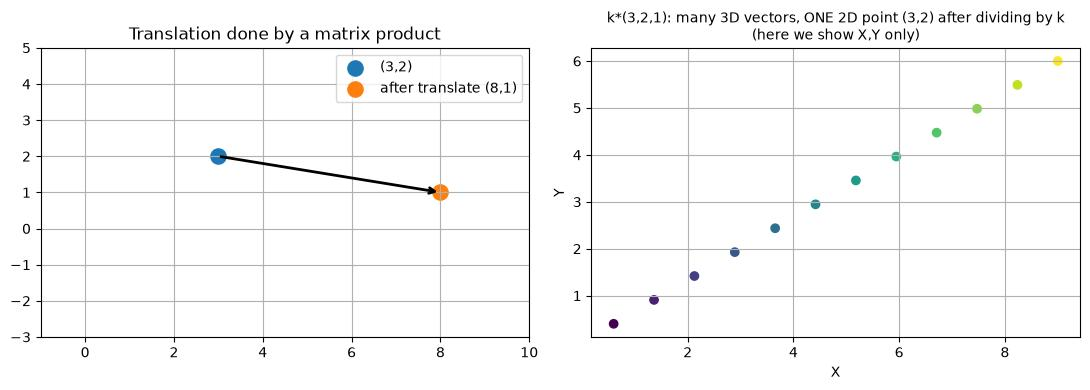

In [8]:
# small picture: the point (3,2) before/after translation and the "same point, many scales" idea
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
new = (M_t @ P)[:2]
ax[0].scatter(*p, s=120, label="(3,2)"); ax[0].scatter(*new, s=120, label=f"after translate ({new[0]:.0f},{new[1]:.0f})")
ax[0].annotate("", xy=new, xytext=p, arrowprops=dict(arrowstyle="->", lw=2))
ax[0].set_xlim(-1, 10); ax[0].set_ylim(-3, 5); ax[0].grid(True); ax[0].legend(); ax[0].set_title("Translation done by a matrix product")
# every multiple k*(3,2,1) lies on one line through the origin in 3D == one 2D point
ks = np.linspace(0.2, 3, 12)
ax[1].scatter(3 * ks, 2 * ks, c=ks, cmap="viridis")
ax[1].set_title("k*(3,2,1): many 3D vectors, ONE 2D point (3,2) after dividing by k\n(here we show X,Y only)", fontsize=10)
ax[1].set_xlabel("X"); ax[1].set_ylabel("Y"); ax[1].grid(True)
plt.tight_layout(); plt.show()

**Answer to (c):** the extra coordinate lets us write *every* geometric transformation (even perspective) as a matrix multiplication,
lets us combine many transformations into one matrix, and lets us represent points at infinity (vanishing points). That is exactly what computer vision needs for camera models, image warping and homographies.

---
# (d) Affine transformation

### The idea
An **affine transformation** is any combination of translation, rotation, scaling and shearing (the last row of the matrix stays `[0 0 1]`):

$$\begin{bmatrix} x' \\ y' \end{bmatrix} = \begin{bmatrix} a & b & t_x \\ c & d & t_y \end{bmatrix}\begin{bmatrix} x \\ y \\ 1 \end{bmatrix}$$

It has **6 unknown numbers**, so **3 point pairs** (source point → destination point) are enough to find it: `cv2.getAffineTransform`.

**Question: do straight lines remain straight?**  **Yes.** Also, parallel lines stay parallel and the ratio of lengths along a line is kept.
(But angles and lengths in general *can* change.)

To make this visible I draw a grid of straight lines on the image, transform the picture and then *measure* the result.

Affine matrix (2x3) found from 3 point pairs:
 [[ 0.626  0.111 60.   ]
 [ 0.104  0.781 40.   ]]


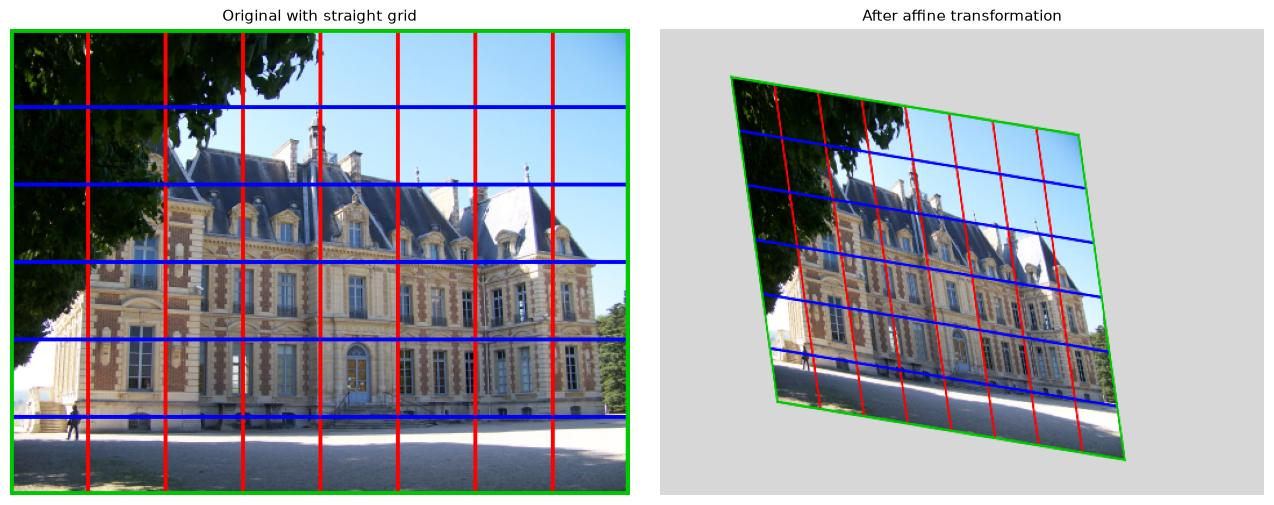

True

In [9]:
# image with a grid of straight lines drawn on it
grid_img = img.copy()
for x in range(0, w, 60):
    cv2.line(grid_img, (x, 0), (x, h - 1), (0, 0, 255), 2)
for y in range(0, h, 60):
    cv2.line(grid_img, (0, y), (w - 1, y), (255, 0, 0), 2)
cv2.rectangle(grid_img, (0, 0), (w - 1, h - 1), (0, 200, 0), 4)

# 3 source points -> 3 destination points
src3 = np.float32([[0, 0], [w - 1, 0], [0, h - 1]])
dst3 = np.float32([[60, 40], [w - 120, 90], [100, h - 40]])
M_aff = cv2.getAffineTransform(src3, dst3)
print("Affine matrix (2x3) found from 3 point pairs:\n", M_aff)

out_w, out_h = w + 40, h + 40
aff = cv2.warpAffine(grid_img, M_aff, (out_w, out_h), borderValue=(215, 215, 215))
show([grid_img, aff], ["Original with straight grid", "After affine transformation"], figsize=(13, 5))
cv2.imwrite("outputs_q1/d_affine.png", aff)

In [10]:
# ------- measure: are lines still straight? are parallel lines still parallel? -------
def apply_aff(M, pts):
    pts = np.asarray(pts, float)
    return (M[:, :2] @ pts.T).T + M[:, 2]

def cross2(a, b):
    return a[0] * b[1] - a[1] * b[0]

# 1) Take 6 points on ONE straight line, transform them and test if they are still on one line
t = np.linspace(0, 1, 6)[:, None]
line_pts = np.array([50, 30]) + t * (np.array([400, 250]) - np.array([50, 30]))
new_pts = apply_aff(M_aff, line_pts)
d0 = new_pts[-1] - new_pts[0]
dev = [abs(cross2(d0, p - new_pts[0])) / np.linalg.norm(d0) for p in new_pts]
print("Max distance of the 6 transformed points from their straight line: %.6f pixels" % max(dev))
print("-> straight lines remain straight:", max(dev) < 1e-6)

# 2) Two parallel lines (two vertical grid lines) -> still parallel?
a1, a2 = np.array([[60, 0], [60, h - 1]], float)
b1, b2 = np.array([[240, 0], [240, h - 1]], float)
da = apply_aff(M_aff, [a2])[0] - apply_aff(M_aff, [a1])[0]
db = apply_aff(M_aff, [b2])[0] - apply_aff(M_aff, [b1])[0]
print("\nDirection of line A after transform:", da, "\nDirection of line B after transform:", db)
print("Cross product (0 means parallel): %.6f" % cross2(da, db))
print("-> parallel lines remain parallel:", abs(cross2(da, db)) < 1e-6)

# 3) What DOES change: angles and lengths
dir_h = apply_aff(M_aff, [[w - 1, 0]])[0] - apply_aff(M_aff, [[0, 0]])[0]
dir_v = apply_aff(M_aff, [[0, h - 1]])[0] - apply_aff(M_aff, [[0, 0]])[0]
cosang = dir_h @ dir_v / (np.linalg.norm(dir_h) * np.linalg.norm(dir_v))
print("\nThe top edge and left edge were 90 deg apart; after transform they are %.1f deg apart" % np.degrees(np.arccos(cosang)))
print("Width of image before: %d px, top edge length after: %.1f px" % (w - 1, np.linalg.norm(dir_h)))

Max distance of the 6 transformed points from their straight line: 0.000000 pixels
-> straight lines remain straight: True

Direction of line A after transform: [ 40. 281.] 
Direction of line B after transform: [ 40. 281.]
Cross product (0 means parallel): 0.000000
-> parallel lines remain parallel: True

The top edge and left edge were 90 deg apart; after transform they are 72.4 deg apart
Width of image before: 479 px, top edge length after: 304.1 px


### What we observe (answer to d)
* **Straight lines remain straight** – the red/blue grid lines are still perfectly straight (measured error ≈ 0 pixels).
* **Parallel lines remain parallel** – the grid lines never start to meet.
* The rectangle became a **parallelogram**: angles are no longer 90° and lengths changed.
  So an affine transform can lean, stretch and rotate a picture, but it **cannot** make parallel lines converge.
  That limitation is the reason we need the projective transformation (homography) in part (e).

---
# (e) Projective transformation (homography): make a slanted book look flat

### The idea
When you photograph a flat book from an angle, parallel edges seem to **converge** (perspective). An affine map cannot create or remove that effect, but a **homography** can.

A homography is a **3×3 matrix** $H$ with **8 free numbers** (it is defined up to scale), so we need **4 point pairs** (the 4 corners of the book):

$$\begin{bmatrix} X \\ Y \\ W \end{bmatrix} = H \begin{bmatrix} x \\ y \\ 1 \end{bmatrix},\qquad x' = X/W,\; y' = Y/W$$

**Plan:**
1. Make a "photo" of a book taken from the side (so we know the truth). *(You can replace this by your own photo – see the note below.)*
2. Mark the 4 corners of the book in the photo (source points).
3. Say "these 4 corners should become a perfect rectangle" (destination points).
4. `cv2.getPerspectiveTransform` → $H$, then `cv2.warpPerspective` → flat book.

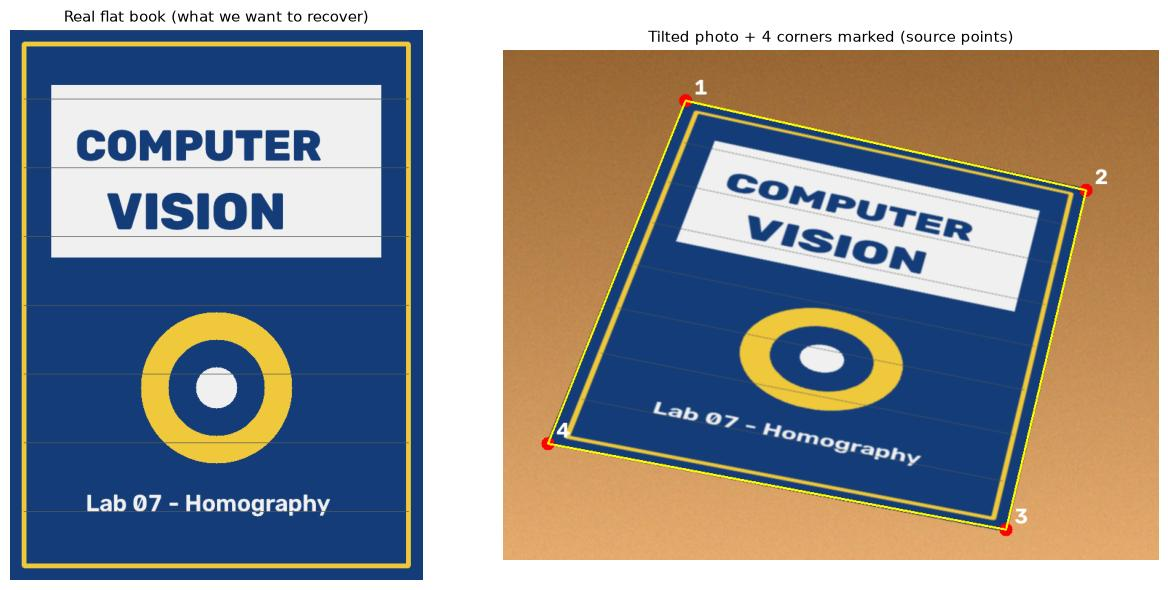

In [11]:
# ---------- 1) create a flat "book cover" (this is what the book really looks like from the front) ----------
BW, BH = 600, 800          # real book proportions (width x height)
cover = np.zeros((BH, BW, 3), np.uint8)
cover[:] = (120, 60, 20)                                           # dark blue cover (BGR)
cv2.rectangle(cover, (20, 20), (BW - 21, BH - 21), (60, 200, 240), 6)          # yellow border
cv2.rectangle(cover, (60, 80), (BW - 61, 330), (240, 240, 240), -1)            # title box
cv2.putText(cover, "COMPUTER", (95, 190), cv2.FONT_HERSHEY_DUPLEX, 2.2, (120, 60, 20), 4)
cv2.putText(cover, "VISION", (140, 290), cv2.FONT_HERSHEY_DUPLEX, 2.6, (120, 60, 20), 5)
cv2.circle(cover, (BW // 2, 520), 110, (60, 200, 240), -1)
cv2.circle(cover, (BW // 2, 520), 70, (120, 60, 20), -1)
cv2.circle(cover, (BW // 2, 520), 30, (240, 240, 240), -1)
cv2.putText(cover, "Lab 07 - Homography", (110, 700), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (240, 240, 240), 3)
# a few straight guide lines so that straightness is easy to check
for y in range(0, BH, 100):
    cv2.line(cover, (20, y), (BW - 21, y), (90, 90, 90), 1)

# ---------- 2) take a "slanted photo" of it: put the book on a table, seen from an angle ----------
PW, PH = 900, 700
rng = np.random.default_rng(0)
table = np.zeros((PH, PW, 3), np.uint8)
for y in range(PH):                                     # wood-like background
    table[y, :] = (40 + y // 12, 90 + y // 10, 140 + y // 9)
table = cv2.add(table, rng.integers(0, 25, table.shape, dtype=np.uint8))

true_quad = np.float32([[250, 70], [800, 190], [690, 660], [60, 540]])      # where the 4 cover corners land in the photo
cover_corners = np.float32([[0, 0], [BW - 1, 0], [BW - 1, BH - 1], [0, BH - 1]])
H_true = cv2.getPerspectiveTransform(cover_corners, true_quad)
warped_cover = cv2.warpPerspective(cover, H_true, (PW, PH))
mask = cv2.warpPerspective(np.full((BH, BW), 255, np.uint8), H_true, (PW, PH))
photo = table.copy()
photo[mask > 0] = warped_cover[mask > 0]
photo = cv2.GaussianBlur(photo, (3, 3), 0)
cv2.imwrite("outputs_q1/e_tilted_book_input.png", photo)

# ---------- 3) the 4 corners a user would click on the photo (add 1-2 px of "clicking error") ----------
clicked = true_quad + rng.normal(0, 1.2, true_quad.shape).astype(np.float32)
photo_marked = photo.copy()
for i, (x, y) in enumerate(clicked):
    cv2.circle(photo_marked, (int(x), int(y)), 9, (0, 0, 255), -1)
    cv2.putText(photo_marked, str(i + 1), (int(x) + 12, int(y) - 8), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 3)
cv2.polylines(photo_marked, [clicked.astype(np.int32)], True, (0, 255, 255), 2)
show([cover, photo_marked], ["Real flat book (what we want to recover)", "Tilted photo + 4 corners marked (source points)"], figsize=(13, 6))

Homography matrix H (3x3):
 [[ 9.48774e-01  3.79592e-01 -2.63677e+02]
 [-3.87747e-01  1.74166e+00 -2.39892e+01]
 [-1.18226e-04  2.31677e-04  1.00000e+00]]

Note the last row is NOT [0 0 1] -> that bottom row is what creates perspective (the 'divide by W').


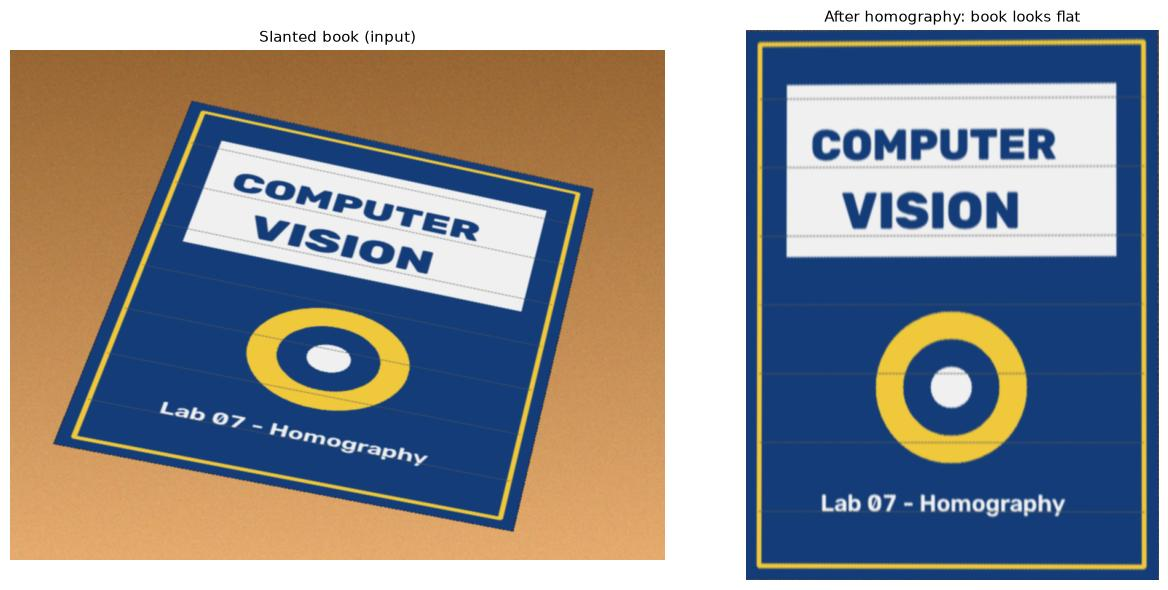

In [12]:
# ---------- 4) the homography ----------
src_pts = clicked                                              # corners in the tilted photo (top-left, top-right, bottom-right, bottom-left)
dst_pts = np.float32([[0, 0], [BW - 1, 0], [BW - 1, BH - 1], [0, BH - 1]])   # perfect rectangle

H = cv2.getPerspectiveTransform(src_pts, dst_pts)
print("Homography matrix H (3x3):\n", np.array2string(H, precision=5, suppress_small=False, floatmode="fixed"))
print("\nNote the last row is NOT [0 0 1] -> that bottom row is what creates perspective (the 'divide by W').")

flat = cv2.warpPerspective(photo, H, (BW, BH))
cv2.imwrite("outputs_q1/e_flat_book.png", flat)

show([photo, flat], ["Slanted book (input)", "After homography: book looks flat"], figsize=(13, 6))

Mean absolute pixel difference to the true flat cover: 7.13 (0 = perfect, 255 = worst)

Corner angles of the book in the TILTED photo (should NOT all be 90):
[99.3, 89.3, 92.6, 78.9]
Corner angles after the homography (should all be ~90):
[90.0, 90.0, 90.0, 90.0]

findHomography gives the same matrix as getPerspectiveTransform? True


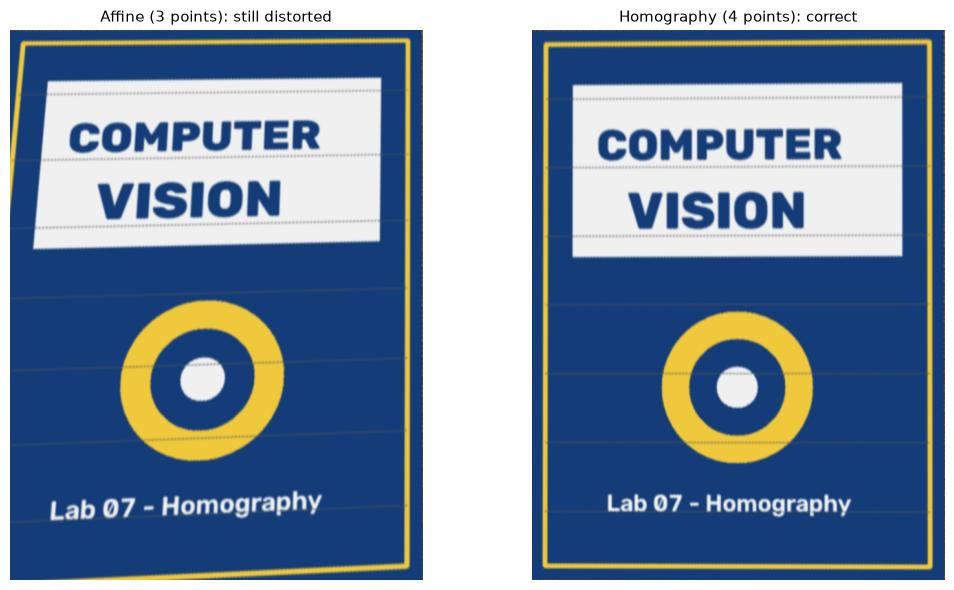

In [13]:
# ---------- 5) how good is it?  compare with the real flat cover ----------
diff = cv2.absdiff(cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY), cv2.cvtColor(cover, cv2.COLOR_BGR2GRAY))
print("Mean absolute pixel difference to the true flat cover: %.2f (0 = perfect, 255 = worst)" % diff.mean())

# ---------- 6) geometry check: are opposite sides parallel and corners 90 degrees? ----------
def angle_at(p_prev, p, p_next):
    a, b = p_prev - p, p_next - p
    return np.degrees(np.arccos(a @ b / (np.linalg.norm(a) * np.linalg.norm(b))))

print("\nCorner angles of the book in the TILTED photo (should NOT all be 90):")
q = clicked.astype(float)
print([round(float(angle_at(q[i - 1], q[i], q[(i + 1) % 4])), 1) for i in range(4)])

q2 = cv2.perspectiveTransform(src_pts.reshape(-1, 1, 2), H).reshape(-1, 2).astype(float)
print("Corner angles after the homography (should all be ~90):")
print([round(float(angle_at(q2[i - 1], q2[i], q2[(i + 1) % 4])), 1) for i in range(4)])

# ---------- 7) same thing with cv2.findHomography (works with MORE than 4 points + RANSAC) ----------
H2, inl = cv2.findHomography(src_pts, dst_pts, method=0)
print("\nfindHomography gives the same matrix as getPerspectiveTransform?", np.allclose(H / H[2, 2], H2 / H2[2, 2], atol=1e-4))

# ---------- 8) compare with an AFFINE transform using only 3 corners: it cannot flatten perspective ----------
M3 = cv2.getAffineTransform(src_pts[:3], dst_pts[:3])
flat_aff = cv2.warpAffine(photo, M3, (BW, BH))
show([flat_aff, flat], ["Affine (3 points): still distorted", "Homography (4 points): correct"], figsize=(11, 6))

### What we observe (answer to e)
* In the photo the book's corners have strange angles and the top/bottom edges lean toward each other (perspective).
* The homography stretches the image in a **non-uniform** way (the divide by $W$) and the result is the book seen **head-on**: all four corners are ≈ 90° and the lines of the cover are straight and parallel again.
* An affine map built from 3 corners cannot do this – the image stays distorted – which shows why homography is needed for perspective.

> **Want to use your own tilted photo?** Replace `photo` with `cv2.imread("my_book.jpg")` and set `clicked` to the four corners
> (top-left, top-right, bottom-right, bottom-left) of the book in that picture – everything else stays the same.
> (Q2 shows how to find those corners automatically.)

---
## Summary: the transformation "family"
| Type | Matrix last row | Straight lines stay straight | Parallel lines stay parallel | Angles kept | Lengths kept | Point pairs needed |
|---|---|---|---|---|---|---|
| Translation + Rotation (rigid) | `0 0 1` | ✔ | ✔ | ✔ | ✔ | 2 |
| Similarity (+ uniform scale) | `0 0 1` | ✔ | ✔ | ✔ | ✘ | 2 |
| **Affine** | `0 0 1` | ✔ | ✔ | ✘ | ✘ | 3 |
| **Projective (homography)** | `g h 1` | ✔ | ✘ | ✘ | ✘ | 4 |